In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler 
from sklearn.metrics import (precision_recall_curve, auc, average_precision_score, classification_report, confusion_matrix)
import lightgbm as lgb

In [4]:
from numpy import dtype
DATA_PATH = "../data/PS_20174392719_1491204439457_log.csv"
dtypes = {  'step': 'int16',
    'type': 'category',
    'amount': 'float32',
    'oldbalanceOrg': 'float32',
    'newbalanceOrig': 'float32',
    'oldbalanceDest': 'float32',
    'newbalanceDest': 'float32',
    'isFraud': 'int8'}

df = pd.read_csv(DATA_PATH,dtype = dtypes, usecols=list(dtypes.keys()) + ['nameOrig', 'nameDest'])
vuln_df = df[df['type'].isin(['TRANSFER', 'CASH_OUT'])].copy()
print(f"Vulnerable transactions (TRANSFER & CASH_OUT): {vuln_df.shape[0]:,} rows")

Vulnerable transactions (TRANSFER & CASH_OUT): 460,394 rows


In [23]:
# Updated Cell 3: Robust Pre-Transaction Domain Features
vuln_df['is_transfer'] = (vuln_df['type'] == 'TRANSFER').astype('int8')
vuln_df['orig_diff'] = vuln_df['amount'] - vuln_df['oldbalanceOrg']
vuln_df['dest_zero'] = (vuln_df['oldbalanceDest'] == 0).astype('int8')
vuln_df['orig_zero'] = (vuln_df['oldbalanceOrg'] == 0).astype('int8')
vuln_df['exact_drain'] = ((np.abs(vuln_df['amount'] - vuln_df['oldbalanceOrg']) < 1.0) & (vuln_df['oldbalanceOrg'] > 0)).astype('int8')

feature_cols = [
    'amount',
    'oldbalanceOrg',
    'oldbalanceDest',
    'is_transfer',
    'orig_diff',
    'dest_zero',
    'orig_zero',
    'exact_drain'
]

print("Updated Features:", feature_cols)


Updated Features: ['amount', 'oldbalanceOrg', 'oldbalanceDest', 'is_transfer', 'orig_diff', 'dest_zero', 'orig_zero', 'exact_drain']


In [24]:
train_mask = vuln_df['step'] <= 65 
val_mask = (vuln_df['step'] > 65) & (vuln_df['step'] <= 80)
test_mask = vuln_df['step'] > 80

In [25]:
# Create updated chronological masks aligned with business cycles
train_mask = vuln_df['step'] <= 35
val_mask = (vuln_df['step'] > 35) & (vuln_df['step'] <= 42)
test_mask = vuln_df['step'] > 42

# Split features (X) and target (y)
X_train = vuln_df.loc[train_mask, feature_cols]
y_train = vuln_df.loc[train_mask, target_col]

X_val = vuln_df.loc[val_mask, feature_cols]
y_val = vuln_df.loc[val_mask, target_col]

X_test = vuln_df.loc[test_mask, feature_cols]
y_test = vuln_df.loc[test_mask, target_col]

print(f"Train set: {X_train.shape[0]:,} rows | Frauds: {y_train.sum():,} ({y_train.mean()*100:.3f}%)")
print(f"Val set:   {X_val.shape[0]:,} rows | Frauds: {y_val.sum():,} ({y_val.mean()*100:.3f}%)")
print(f"Test set:  {X_test.shape[0]:,} rows | Frauds: {y_test.sum():,} ({y_test.mean()*100:.3f}%)")


Train set: 288,668 rows | Frauds: 398 (0.138%)
Val set:   112,178 rows | Frauds: 100 (0.089%)
Test set:  59,548 rows | Frauds: 644 (1.081%)


In [26]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.fit_transform(X_val)

baseline_lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
baseline_lr.fit(X_train_scaled, y_train)

y_val_proba_lr = baseline_lr.predict_proba(X_val_scaled)[:,1]

pr_auc_lr = average_precision_score(y_val, y_val_proba_lr)
print(f"Baseline logistic Regression PR-AUC: {pr_auc_lr:.4f}")

Baseline logistic Regression PR-AUC: 0.9726


Calculated scale_pos_weight: 724.3
[LightGBM] [Info] Number of positive: 398, number of negative: 288270
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001725 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1028
[LightGBM] [Info] Number of data points in the train set: 288668, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.001379 -> initscore=-6.585201
[LightGBM] [Info] Start training from score -6.585201
Baseline Logistic regression PR-AUC: 0.9726
LightGBM PR-AUC: 0.9706


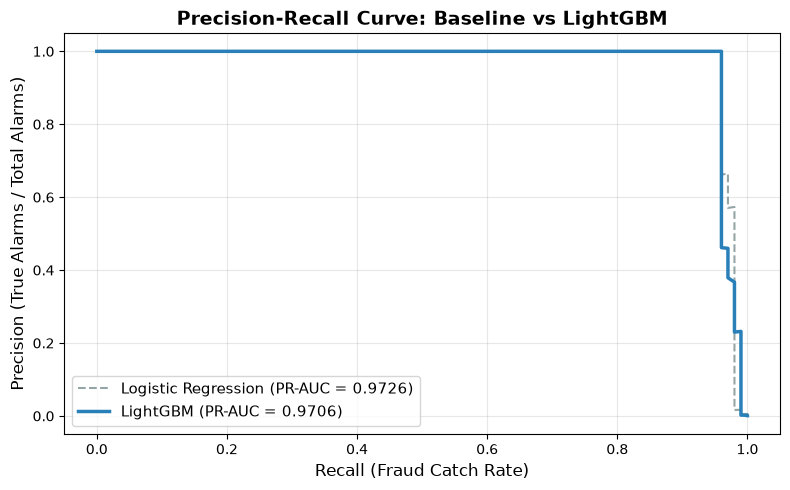

In [29]:
from cProfile import label
#class imbalance ratio calculating
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos = neg_count / pos_count
print(f'Calculated scale_pos_weight: {scale_pos:.1f}')

lgb_model = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1
)

lgb_model.fit(X_train, y_train)

#predict probabilities on valiadtion set
y_val_proba_lgb = lgb_model.predict_proba(X_val)[:,1]

pr_auc_lgb = average_precision_score(y_val, y_val_proba_lgb)
print(f"Baseline Logistic regression PR-AUC: {pr_auc_lr:.4f}")
print(f"LightGBM PR-AUC: {pr_auc_lgb:.4f}")

prec_lr, rec_lr, _ = precision_recall_curve(y_val,y_val_proba_lr)
prec_lgb, rec_lgb, _ = precision_recall_curve(y_val, y_val_proba_lgb)

plt.figure(figsize=(8, 5))
plt.plot(rec_lr, prec_lr, label=f'Logistic Regression (PR-AUC = {pr_auc_lr:.4f})', color='#95a5a6', linestyle='--')
plt.plot(rec_lgb, prec_lgb, label=f'LightGBM (PR-AUC = {pr_auc_lgb:.4f})', color='#2980b9', linewidth=2.5)
plt.xlabel('Recall (Fraud Catch Rate)', fontsize=12)
plt.ylabel('Precision (True Alarms / Total Alarms)', fontsize=12)
plt.title('Precision-Recall Curve: Baseline vs LightGBM', fontsize=14, fontweight='bold')
plt.legend(loc='lower left', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


OPTIMAL DECISION THRESHOLD: 0.4258
Minimum Total Cost:    $20,000.00
Recall (Catch Rate):   96.00% (96 of 100 frauds caught)
False Negatives:       4 frauds missed
Precision:             100.00%
False Positives:       0 innocent customers flagged
Alert Rate:            0.0856% of total traffic


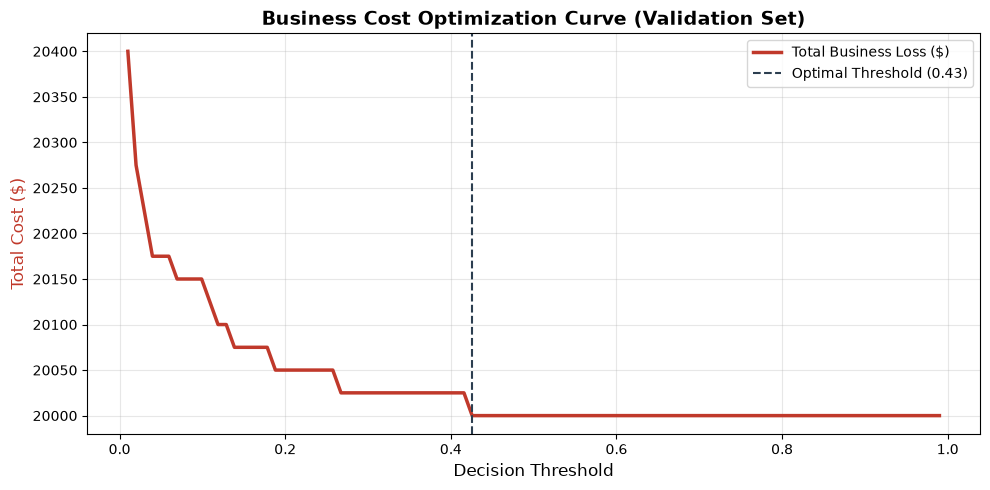

In [30]:
# Step 2.4: Sweep Decision Thresholds on the Validation Set
thresholds = np.linspace(0.01, 0.99, 100)

cost_fn = 5000.0  # Conservative average loss per missed fraud ($5,000)
cost_fp = 25.0    # Customer support triage & friction cost per false alarm ($25)

results = []

for t in thresholds:
    # Binary predictions at threshold t
    y_pred = (y_val_proba_lgb >= t).astype(int)
    
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()
    
    total_cost = (fn * cost_fn) + (fp * cost_fp)
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    alert_rate = (tp + fp) / len(y_val) * 100  # Percentage of transactions flagged
    
    results.append({
        'threshold': t,
        'total_cost': total_cost,
        'recall': recall,
        'precision': precision,
        'alert_rate_pct': alert_rate,
        'tp': tp,
        'fp': fp,
        'fn': fn
    })

cost_df = pd.DataFrame(results)

# Find the threshold that minimizes financial loss
optimal_row = cost_df.loc[cost_df['total_cost'].idxmin()]
best_threshold = optimal_row['threshold']

print("=" * 60)
print(f"OPTIMAL DECISION THRESHOLD: {best_threshold:.4f}")
print("=" * 60)
print(f"Minimum Total Cost:    ${optimal_row['total_cost']:,.2f}")
print(f"Recall (Catch Rate):   {optimal_row['recall']*100:.2f}% ({int(optimal_row['tp'])} of 100 frauds caught)")
print(f"False Negatives:       {int(optimal_row['fn'])} frauds missed")
print(f"Precision:             {optimal_row['precision']*100:.2f}%")
print(f"False Positives:       {int(optimal_row['fp'])} innocent customers flagged")
print(f"Alert Rate:            {optimal_row['alert_rate_pct']:.4f}% of total traffic")

# Plot Cost vs Threshold
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(cost_df['threshold'], cost_df['total_cost'], color='#c0392b', linewidth=2.5, label='Total Business Loss ($)')
ax1.axvline(x=best_threshold, color='#2c3e50', linestyle='--', label=f'Optimal Threshold ({best_threshold:.2f})')
ax1.set_xlabel('Decision Threshold', fontsize=12)
ax1.set_ylabel('Total Cost ($)', color='#c0392b', fontsize=12)
ax1.set_title('Business Cost Optimization Curve (Validation Set)', fontsize=14, fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [40]:
# Step 2.5: Final Out-of-Time Test Evaluation
print("=" * 60)
print("FINAL HELD-OUT TEST EVALUATION (Steps 43 - 95)")
print("=" * 60)

# 1. Predict probabilities on unseen test set
y_test_proba_lgb = lgb_model.predict_proba(X_test)[:, 1]

# 2. PR-AUC on Test
test_pr_auc = average_precision_score(y_test, y_test_proba_lgb)
print(f"Test Set PR-AUC: {test_pr_auc:.4f}\n")

# 3. Apply the frozen optimal threshold (0.43)
y_test_pred = (y_test_proba_lgb >= best_threshold).astype(int)

# 4. Confusion Matrix & Metrics
tn_test, fp_test, fn_test, tp_test = confusion_matrix(y_test, y_test_pred).ravel()

test_recall = tp_test / (tp_test + fn_test)
test_precision = tp_test / (tp_test + fp_test)
test_alert_rate = (tp_test + fp_test) / len(y_test) * 100

print(f"Total Test Transactions: {len(y_test):,}")
print(f"Total Frauds Present:    {int(y_test.sum())}")
print("-" * 60)
print(f"Frauds Caught (TP):      {tp_test} ({test_recall*100:.2f}% Recall)")
print(f"Frauds Missed (FN):      {fn_test}")
print(f"False Alarms (FP):       {fp_test} ({test_precision*100:.2f}% Precision)")
print(f"Alert Rate:              {test_alert_rate:.3f}% of total test traffic")
print("=" * 60)

# 5. Export Model Artifact for Live Kafka Streaming Consumer
model_path = "../models/fraud_detector_lgbm.joblib"
joblib.dump(lgb_model, model_path)
print(f" Model artifact successfully exported to: {model_path}")

# Export metadata config for the scoring consumer
import json
metadata = {
    "model_name": "LightGBM_Fraud_Detector_v1",
    "features": feature_cols,
    "optimal_threshold": round(best_threshold, 4),
    "test_pr_auc": round(test_pr_auc, 4),
    "test_recall": round(test_recall, 4),
    "test_precision": round(test_precision, 4)
}

with open("../models/model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print(" Metadata config successfully exported to: ../models/model_metadata.json")


FINAL HELD-OUT TEST EVALUATION (Steps 43 - 95)
Test Set PR-AUC: 0.9971

Total Test Transactions: 59,548
Total Frauds Present:    644
------------------------------------------------------------
Frauds Caught (TP):      641 (99.53% Recall)
Frauds Missed (FN):      3
False Alarms (FP):       0 (100.00% Precision)
Alert Rate:              1.076% of total test traffic
 Model artifact successfully exported to: ../models/fraud_detector_lgbm.joblib
 Metadata config successfully exported to: ../models/model_metadata.json
